# Giá trị khách hàng & nhắm mục tiêu khuyến mãi — Online Retail II
## Đặc trưng RFM, cohort view và phân khúc giá trị khách hàng

**Câu hỏi kinh doanh:** Nên ưu tiên khách hàng nào cho hoạt động giữ chân hoặc khuyến mãi để tăng biên lợi nhuận kỳ vọng trong tương lai mà không giảm giá quá mức?

**Đầu vào:** `obs_transactions_*.csv` và `modeling_base_*.csv` do `01_cleaning_and_windows.ipynb` tạo ra.

**Nguyên tắc của notebook này:**
1. R, F, M và nhóm khách **chỉ tính từ cửa sổ quan sát** (12 tháng trước cutoff), nên có thể dựng đúng như vậy tại thời điểm ra quyết định.
2. Ngưỡng của nhóm được **đọc từ dữ liệu train rồi đóng băng**, sau đó áp nguyên lên test.
3. Nhãn tương lai (`repeat_purchase`, `future_net_spend`) **không dùng để tạo nhóm**, chỉ dùng để kiểm chứng xem nhóm có thực sự khác nhau về hành vi sau cutoff hay không.
4. Nhóm được gán bằng **luật if/else trên số liệu thô**, không dùng thang điểm hay thuật toán phân cụm.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)

# Same snapshots as 01_cleaning_and_windows.ipynb
SNAPSHOTS = {"train": pd.Timestamp("2010-12-10"), "test": pd.Timestamp("2011-06-10")}
COLORS = {"train": "tab:blue", "test": "tab:orange"}

In [2]:
obs, base = {}, {}
for name, cutoff in SNAPSHOTS.items():
    obs[name] = pd.read_csv(f"obs_transactions_{name}.csv", parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})
    base[name] = pd.read_csv(f"modeling_base_{name}.csv", parse_dates=["snapshot_cutoff", "obs_start", "first_seen", "last_seen"])
    # Leakage guard: features may only use rows before the cutoff
    assert obs[name]["InvoiceDate"].max() < cutoff
    assert (base[name]["in_population"] == 1).all()
    print(f"{name}: {len(obs[name]):,} observation rows | {len(base[name]):,} customers in population | cutoff {cutoff.date()}")

train: 392,669 observation rows | 4,223 customers in population | cutoff 2010-12-10


test: 374,480 observation rows | 4,323 customers in population | cutoff 2011-06-10


## 8. Đặc trưng RFM tại mỗi cutoff

### 8.1 Định nghĩa

| Đặc trưng | Định nghĩa | Lý do |
|---|---|---|
| `recency_days` (R) | Số ngày từ lần **mua** cuối đến cutoff | Tính so với cutoff vì cutoff là "hôm nay" của thử nghiệm. Hóa đơn trả hàng không tính là hoạt động mua |
| `frequency` (F) | Số hóa đơn bán khác nhau trong cửa sổ quan sát | Khớp với `n_sales_invoices_obs` và với mốc 1 / 2-3 / 4+ ở mục 6.13 |
| `monetary` (M) | Doanh số bán trừ hàng trả trong cửa sổ, sàn ở 0 | Cùng định nghĩa với nhãn `future_net_spend`, nên giá trị quá khứ và tương lai so sánh được |
| `purchase_days` | Số ngày mua khác nhau | Đối chiếu với F (khách bán buôn có thể xuất nhiều hóa đơn trong một ngày) |
| `avg_order_value` | Doanh số bán / F | Phân biệt khách đơn lớn với khách đơn nhỏ |
| `return_rate` | Giá trị hàng trả / doanh số bán | Hàng trả làm hao hụt biên lợi nhuận |
| `tenure_days` | Số ngày từ lần đầu xuất hiện đến cutoff | Khách lâu năm hay khách mới |

In [3]:
def build_rfm(obs_rows, base_rows, cutoff):
    sales = obs_rows[~obs_rows["is_return"]]
    returns = obs_rows[obs_rows["is_return"]]
    g = sales.groupby("CustomerID")

    rfm = pd.DataFrame({
        "recency_days": (cutoff - g["InvoiceDate"].max()).dt.days,
        "frequency": g["Invoice"].nunique(),
        "purchase_days": g["InvoiceDate"].apply(lambda d: d.dt.normalize().nunique()),
        "gross_sales": g["Revenue"].sum(),
    })
    rfm["return_value"] = -returns.groupby("CustomerID")["Revenue"].sum()
    rfm["return_value"] = rfm["return_value"].fillna(0)
    rfm["monetary"] = (rfm["gross_sales"] - rfm["return_value"]).clip(lower=0)
    rfm["avg_order_value"] = rfm["gross_sales"] / rfm["frequency"]
    rfm["return_rate"] = rfm["return_value"] / rfm["gross_sales"]

    b = base_rows.set_index("CustomerID")
    rfm = rfm.reindex(b.index)                       # population only, same order as the modeling base
    rfm["tenure_days"] = (cutoff - b["first_seen"]).dt.days
    return rfm.reset_index()

rfm = {name: build_rfm(obs[name], base[name], c) for name, c in SNAPSHOTS.items()}
for name in SNAPSHOTS:
    assert rfm[name][["recency_days", "frequency", "monetary"]].notna().all().all()
    assert len(rfm[name]) == len(base[name])

rfm["train"][["recency_days", "frequency", "purchase_days", "monetary", "avg_order_value", "return_rate", "tenure_days"]] \
    .describe(percentiles=[.25, .5, .75, .9, .95, .99])

,recency_days,frequency,purchase_days,monetary,avg_order_value,return_rate,tenure_days
count,"4,223.00","4,223.00","4,223.00","4,223.00","4,223.00","4,223.00","4,223.00"
mean,85.45,4.31,3.83,"1,910.82",376.21,0.02,224.50
std,90.88,7.66,5.76,"8,343.84",487.53,0.08,119.45
min,0.00,1.00,1.00,0.00,1.55,0.00,0.00
25%,17.00,1.00,1.00,299.98,179.61,0.00,115.00
50%,50.00,2.00,2.00,667.83,286.39,0.00,252.00
75%,126.50,5.00,4.00,"1,623.29",422.03,0.01,330.00
90%,238.00,9.00,8.00,"3,514.60",664.90,0.05,368.00
95%,283.90,13.00,11.00,"5,836.09",910.95,0.11,371.00
99%,357.00,30.00,23.78,"18,865.15","1,949.89",0.37,373.00


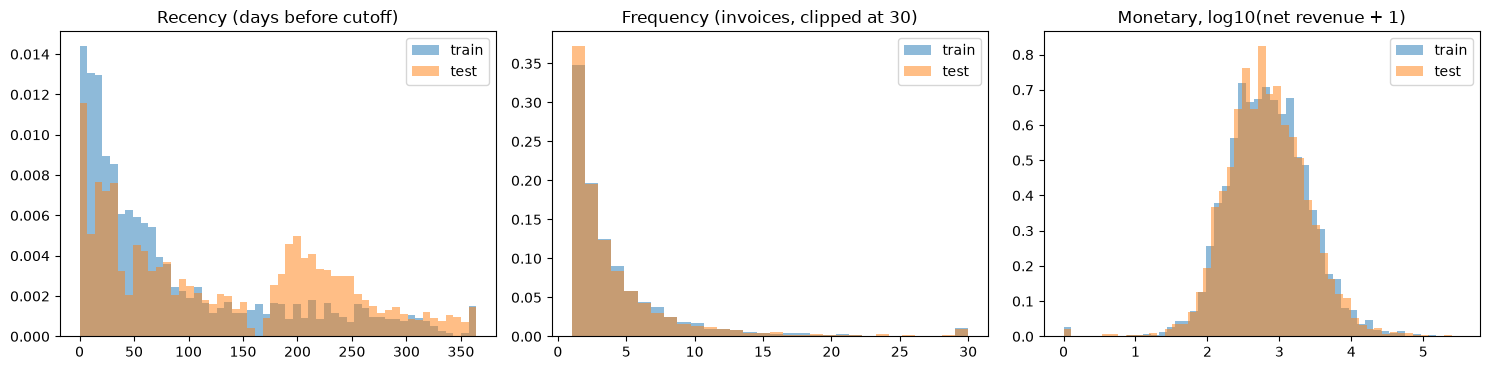

train   0.19
test    0.18
Name: share F != purchase_days, dtype: float64

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for name in SNAPSHOTS:
    r = rfm[name]
    axes[0].hist(r["recency_days"], bins=52, alpha=.5, color=COLORS[name], label=name, density=True)
    axes[1].hist(r["frequency"].clip(upper=30), bins=30, alpha=.5, color=COLORS[name], label=name, density=True)
    axes[2].hist(np.log10(r["monetary"] + 1), bins=50, alpha=.5, color=COLORS[name], label=name, density=True)
axes[0].set_title("Recency (days before cutoff)")
axes[1].set_title("Frequency (invoices, clipped at 30)")
axes[2].set_title("Monetary, log10(net revenue + 1)")
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

share_diff = pd.Series({n: (r["frequency"] != r["purchase_days"]).mean() for n, r in rfm.items()}, name="share F != purchase_days")
share_diff

**Nhận xét:** cả ba chỉ số lệch phải mạnh, đặc biệt là M. Phân phối R của test dịch sang phải so với train: cửa sổ quan sát của test chứa mùa cao điểm Q4-2010, nên có nhiều khách chỉ mua một lần trong mùa đó rồi chưa quay lại. Khoảng 18-19% khách có F khác `purchase_days`, nghĩa là có nhiều hóa đơn trong cùng một ngày. Notebook dùng F theo hóa đơn để khớp với notebook 01.

### 8.2 Đặt ngưỡng từ dữ liệu train

Mỗi ngưỡng có một nguồn bằng chứng:
* **R:** mốc 90 ngày và 180 ngày từ mục 6.9 (71% khách có trung vị khoảng cách mua ≤ 90 ngày, 93% ≤ 180 ngày). Quá 90 ngày là khách bắt đầu "nguội", quá 180 ngày là gần như đã rời đi.
* **F:** mốc 1 / 2-3 / 4+ hóa đơn từ mục 6.13.
* **M:** đường cong tập trung doanh thu (Pareto) trên train. Ngưỡng "giá trị cao" là mức doanh thu của top 10% khách.

Các ngưỡng được tính **một lần trên train**, lưu thành số tuyệt đối và áp nguyên lên test.

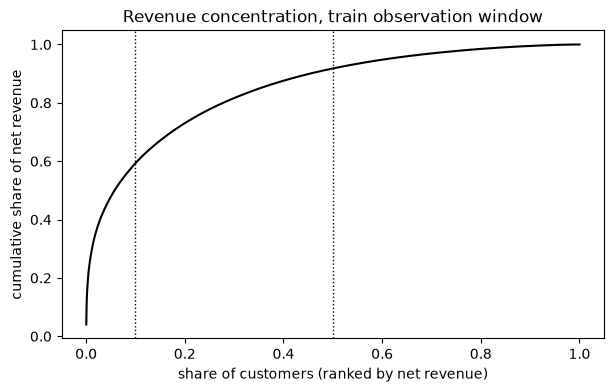

,monetary_threshold,share_of_revenue
customers,,
top 1%,"19,259.99",0.28
top 5%,"5,836.86",0.48
top 10%,"3,521.58",0.59
top 20%,"2,025.56",0.73
top 30%,"1,337.40",0.82
top 50%,668.50,0.92


In [5]:
m = rfm["train"]["monetary"].sort_values(ascending=False).reset_index(drop=True)
cum_share = m.cumsum() / m.sum()
pareto = pd.DataFrame({
    "monetary_threshold": [m.iloc[int(len(m) * q) - 1] for q in (.01, .05, .10, .20, .30, .50)],
    "share_of_revenue": [cum_share.iloc[int(len(m) * q) - 1] for q in (.01, .05, .10, .20, .30, .50)],
}, index=pd.Index(["top 1%", "top 5%", "top 10%", "top 20%", "top 30%", "top 50%"], name="customers"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(m) + 1) / len(m), cum_share, color="black")
for q in (.1, .5):
    ax.axvline(q, color="k", ls=":", lw=1)
ax.set_xlabel("share of customers (ranked by net revenue)"); ax.set_ylabel("cumulative share of net revenue")
ax.set_title("Revenue concentration, train observation window"); plt.show()
pareto

In [6]:
# Thresholds are fitted on train only and frozen
THRESHOLDS = {
    "recency_active": 90,                                          # days, from 6.9
    "recency_lapsed": 180,                                         # days, from 6.9
    "freq_repeat": 2,                                              # invoices, from 6.13
    "freq_loyal": 4,                                               # invoices, from 6.13
    "monetary_high": rfm["train"]["monetary"].quantile(.90),       # top 10% of train
}
THRESHOLDS

{'recency_active': 90,
 'recency_lapsed': 180,
 'freq_repeat': 2,
 'freq_loyal': 4,
 'monetary_high': np.float64(3514.602000000003)}

In [7]:
# Each axis on its own already separates future behaviour (train)
tr = rfm["train"].merge(base["train"][["CustomerID", "repeat_purchase", "future_net_spend"]], on="CustomerID")
bands = {
    "recency": pd.cut(tr["recency_days"], [-1, 90, 180, 400], labels=["<=90d", "91-180d", ">180d"]),
    "frequency": pd.cut(tr["frequency"], [0, 1, 3, np.inf], labels=["1", "2-3", "4+"]),
    "monetary": pd.cut(tr["monetary"], [-1, tr["monetary"].median(), THRESHOLDS["monetary_high"], np.inf],
                       labels=["below median", "median-top10%", "top 10%"]),
}
pd.concat({axis: tr.groupby(b, observed=True).agg(customers=("CustomerID", "size"),
                                                   repeat_rate=("repeat_purchase", "mean"),
                                                   mean_future_net_spend=("future_net_spend", "mean"))
           for axis, b in bands.items()})

customers  repeat_rate  mean_future_net_spend
recency   <=90d               2875         0.56                 827.16
          91-180d              599         0.33                 213.08
          >180d                749         0.23                 105.53
frequency 1                   1423         0.22                  97.75
          2-3                 1313         0.42                 257.83
          4+                  1487         0.75               1,417.04
monetary  below median        2112         0.28                 100.10
          median-top10%       1688         0.60                 465.39
          top 10%              423         0.88               3,753.60

### 8.3 Luật phân nhóm

Các điều kiện được xét **theo thứ tự**: khách rơi vào điều kiện đầu tiên đúng. Nhờ vậy các nhóm loại trừ nhau và phủ hết mọi khách.

| # | Nhóm | Điều kiện | Ý nghĩa |
|---|---|---|---|
| 1 | Champions | M ≥ top 10% **và** R ≤ 90 | Giá trị cao nhất, đang hoạt động |
| 2 | VIP at risk | M ≥ top 10% **và** R > 90 | Từng giá trị cao nhưng đã lâu không mua |
| 3 | Loyal | R ≤ 90 **và** F ≥ 4 | Mua đều, giá trị vừa |
| 4 | Developing | R ≤ 90 **và** F = 2-3 | Đã mua lại, chưa thành thói quen |
| 5 | One-time recent | R ≤ 90 **và** F = 1 | Mới mua một lần gần đây |
| 6 | Cooling | 90 < R ≤ 180 | Đang nguội |
| 7 | Lapsed | R > 180 | Gần như đã rời đi |

In [8]:
SEGMENTS = ["Champions", "VIP at risk", "Loyal", "Developing", "One-time recent", "Cooling", "Lapsed"]

def assign_segment(r, t=THRESHOLDS):
    high_value = r["monetary"] >= t["monetary_high"]
    active = r["recency_days"] <= t["recency_active"]
    conditions = [
        high_value & active,
        high_value,
        active & (r["frequency"] >= t["freq_loyal"]),
        active & (r["frequency"] >= t["freq_repeat"]),
        active,
        r["recency_days"] <= t["recency_lapsed"],
    ]
    seg = np.select(conditions, SEGMENTS[:-1], default=SEGMENTS[-1])
    return pd.Categorical(seg, categories=SEGMENTS, ordered=True)

for name in SNAPSHOTS:
    rfm[name]["segment"] = assign_segment(rfm[name])
    assert rfm[name]["segment"].notna().all()

pd.DataFrame({name: rfm[name]["segment"].value_counts().reindex(SEGMENTS) for name in SNAPSHOTS})

,train,test
segment,,
Champions,388,366
VIP at risk,35,37
Loyal,959,753
Developing,880,527
One-time recent,648,338
Cooling,578,635
Lapsed,735,1667


### 8.4 Hồ sơ nhóm và kiểm chứng trên train

Với mỗi nhóm: quy mô, đặc điểm quá khứ (R, F, M, trả hàng) và **hành vi thực tế trong 6 tháng sau cutoff**. Nhóm chỉ có giá trị nếu các cột tương lai khác nhau rõ giữa các nhóm.

In [9]:
def segment_profile(name):
    d = rfm[name].merge(base[name][["CustomerID", "repeat_purchase", "future_net_spend"]], on="CustomerID", validate="1:1")
    p = d.groupby("segment", observed=False).agg(
        customers=("CustomerID", "size"),
        median_recency=("recency_days", "median"),
        median_frequency=("frequency", "median"),
        mean_monetary=("monetary", "mean"),
        mean_return_rate=("return_rate", "mean"),
        past_revenue=("monetary", "sum"),
        repeat_rate=("repeat_purchase", "mean"),
        mean_future_net_spend=("future_net_spend", "mean"),
        future_revenue=("future_net_spend", "sum"),
    )
    p.insert(1, "share_customers", p["customers"] / p["customers"].sum())
    p["share_past_revenue"] = p.pop("past_revenue") / d["monetary"].sum()
    p["share_future_revenue"] = p.pop("future_revenue") / d["future_net_spend"].sum()
    p["future_spend_lift"] = p["mean_future_net_spend"] / d["future_net_spend"].mean()
    return p

profile = {name: segment_profile(name) for name in SNAPSHOTS}
profile["train"]

,customers,share_customers,median_recency,median_frequency,mean_monetary,mean_return_rate,repeat_rate,mean_future_net_spend,share_past_revenue,share_future_revenue,future_spend_lift
segment,,,,,,,,,,,
Champions,388,0.09,10.00,12.00,"11,711.46",0.02,0.91,"4,002.43",0.56,0.60,6.54
VIP at risk,35,0.01,127.00,5.00,"7,033.39",0.03,0.46,995.11,0.03,0.01,1.63
Loyal,959,0.23,20.00,6.00,"1,728.75",0.02,0.73,553.35,0.21,0.21,0.90
Developing,880,0.21,31.00,2.00,796.21,0.02,0.45,252.01,0.09,0.09,0.41
One-time recent,648,0.15,42.50,1.00,354.18,0.02,0.25,112.21,0.03,0.03,0.18
Cooling,578,0.14,128.00,2.00,677.25,0.03,0.31,166.56,0.05,0.04,0.27
Lapsed,735,0.17,252.00,1.00,407.69,0.03,0.23,102.82,0.04,0.03,0.17


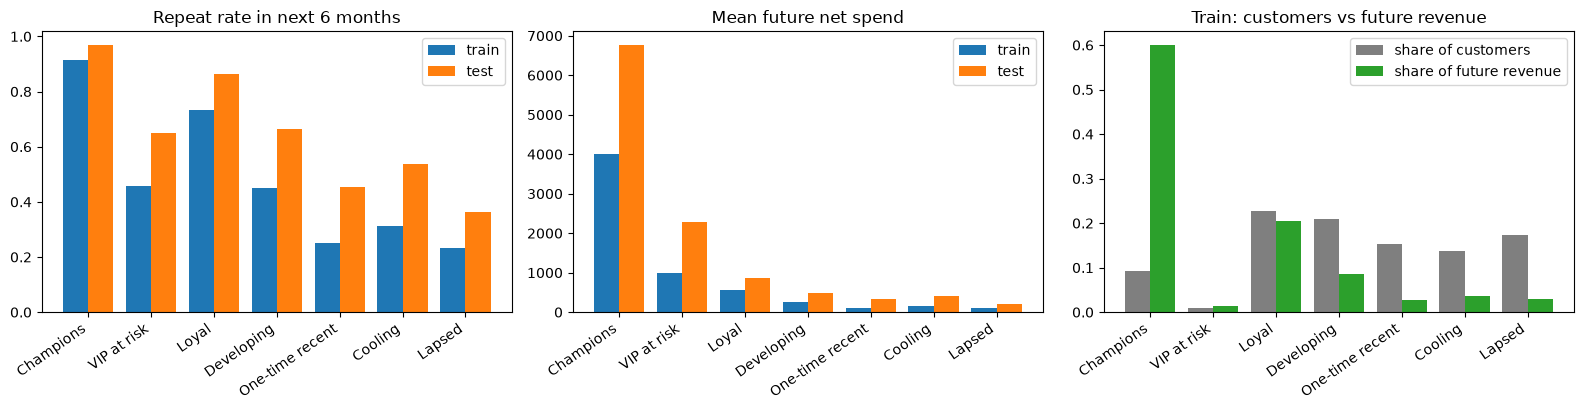

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(SEGMENTS))
for i, name in enumerate(SNAPSHOTS):
    p = profile[name]
    axes[0].bar(x + (i - .5) * .4, p["repeat_rate"], width=.4, color=COLORS[name], label=name)
    axes[1].bar(x + (i - .5) * .4, p["mean_future_net_spend"], width=.4, color=COLORS[name], label=name)
p = profile["train"]
axes[2].bar(x - .2, p["share_customers"], width=.4, color="tab:gray", label="share of customers")
axes[2].bar(x + .2, p["share_future_revenue"], width=.4, color="tab:green", label="share of future revenue")
titles = ["Repeat rate in next 6 months", "Mean future net spend", "Train: customers vs future revenue"]
for ax, t in zip(axes, titles):
    ax.set_xticks(x); ax.set_xticklabels(SEGMENTS, rotation=35, ha="right"); ax.set_title(t); ax.legend()
plt.tight_layout(); plt.show()

### 8.5 Ổn định trên test

Áp **đúng các ngưỡng của train** lên snapshot test, không tính lại. Hai snapshot khác mùa vụ (tỷ lệ mua lại chung 47% so với 57%), nên chỉ so **thứ hạng** và **lift** của các nhóm, không so mức tuyệt đối.

In [11]:
profile["test"]

,customers,share_customers,median_recency,median_frequency,mean_monetary,mean_return_rate,repeat_rate,mean_future_net_spend,share_past_revenue,share_future_revenue,future_spend_lift
segment,,,,,,,,,,,
Champions,366,0.08,17.00,12.00,"11,360.72",0.02,0.97,"6,772.19",0.54,0.59,6.97
VIP at risk,37,0.01,176.00,6.00,"8,147.57",0.05,0.65,"2,293.53",0.04,0.02,2.36
Loyal,753,0.17,27.00,6.00,"1,770.38",0.02,0.86,857.68,0.17,0.15,0.88
Developing,527,0.12,34.00,2.00,803.65,0.02,0.66,486.38,0.05,0.06,0.50
One-time recent,338,0.08,49.00,1.00,326.39,0.01,0.46,332.94,0.01,0.03,0.34
Cooling,635,0.15,125.00,2.00,851.49,0.03,0.54,417.77,0.07,0.06,0.43
Lapsed,1667,0.39,232.00,1.00,514.52,0.02,0.36,213.53,0.11,0.08,0.22


In [12]:
from scipy.stats import spearmanr

compare = pd.DataFrame({
    "repeat_rate_train": profile["train"]["repeat_rate"],
    "repeat_rate_test": profile["test"]["repeat_rate"],
    "lift_train": profile["train"]["future_spend_lift"],
    "lift_test": profile["test"]["future_spend_lift"],
    "share_customers_train": profile["train"]["share_customers"],
    "share_customers_test": profile["test"]["share_customers"],
})
rho_repeat = spearmanr(compare["repeat_rate_train"], compare["repeat_rate_test"]).statistic
rho_lift = spearmanr(compare["lift_train"], compare["lift_test"]).statistic
print(f"Spearman rank correlation across segments, train vs test: repeat rate {rho_repeat:.2f} | future spend lift {rho_lift:.2f}")
compare

Spearman rank correlation across segments, train vs test: repeat rate 0.96 | future spend lift 1.00


,repeat_rate_train,repeat_rate_test,lift_train,lift_test,share_customers_train,share_customers_test
segment,,,,,,
Champions,0.91,0.97,6.54,6.97,0.09,0.08
VIP at risk,0.46,0.65,1.63,2.36,0.01,0.01
Loyal,0.73,0.86,0.90,0.88,0.23,0.17
Developing,0.45,0.66,0.41,0.50,0.21,0.12
One-time recent,0.25,0.46,0.18,0.34,0.15,0.08
Cooling,0.31,0.54,0.27,0.43,0.14,0.15
Lapsed,0.23,0.36,0.17,0.22,0.17,0.39


In [13]:
# Where do customers present in both snapshots move? (rows: train segment, columns: test segment)
both = rfm["train"][["CustomerID", "segment"]].merge(rfm["test"][["CustomerID", "segment"]], on="CustomerID", suffixes=("_train", "_test"))
print(f"Customers in both snapshots: {len(both):,}")
pd.crosstab(both["segment_train"], both["segment_test"], normalize="index")

Customers in both snapshots: 3,657


segment_test,Champions,VIP at risk,Loyal,Developing,One-time recent,Cooling,Lapsed
segment_train,,,,,,,
Champions,0.72,0.09,0.10,0.00,0.00,0.04,0.04
VIP at risk,0.32,0.05,0.18,0.09,0.00,0.14,0.23
Loyal,0.05,0.00,0.49,0.04,0.00,0.15,0.27
Developing,0.01,0.00,0.15,0.13,0.00,0.15,0.55
One-time recent,0.00,0.00,0.03,0.13,0.00,0.08,0.75
Cooling,0.00,0.00,0.06,0.16,0.00,0.08,0.69
Lapsed,0.00,0.00,0.04,0.20,0.36,0.32,0.07


### 8.6 Cohort view: giữ chân theo tháng mua đầu tiên

Phần này **thuần mô tả**, không đưa vào mô hình, nên dùng toàn bộ `clean_transactions.csv`. Mỗi cohort là nhóm khách có lần mua đầu tiên trong cùng một tháng. Ô (cohort, k) là tỷ lệ khách của cohort đó có mua trong tháng thứ k sau tháng đầu tiên.

**Lưu ý:**
* Dữ liệu bắt đầu từ 2009-12, nên cohort 2009-12 gồm cả khách đã mua từ trước đó, và tỷ lệ giữ chân của cohort này cao hơn thực tế của một cohort khách mới.
* Tháng 2011-12 chỉ có dữ liệu đến ngày 9, nên ô cuối cùng của mỗi hàng (đường chéo cuối của ma trận) thấp hơn thực tế.

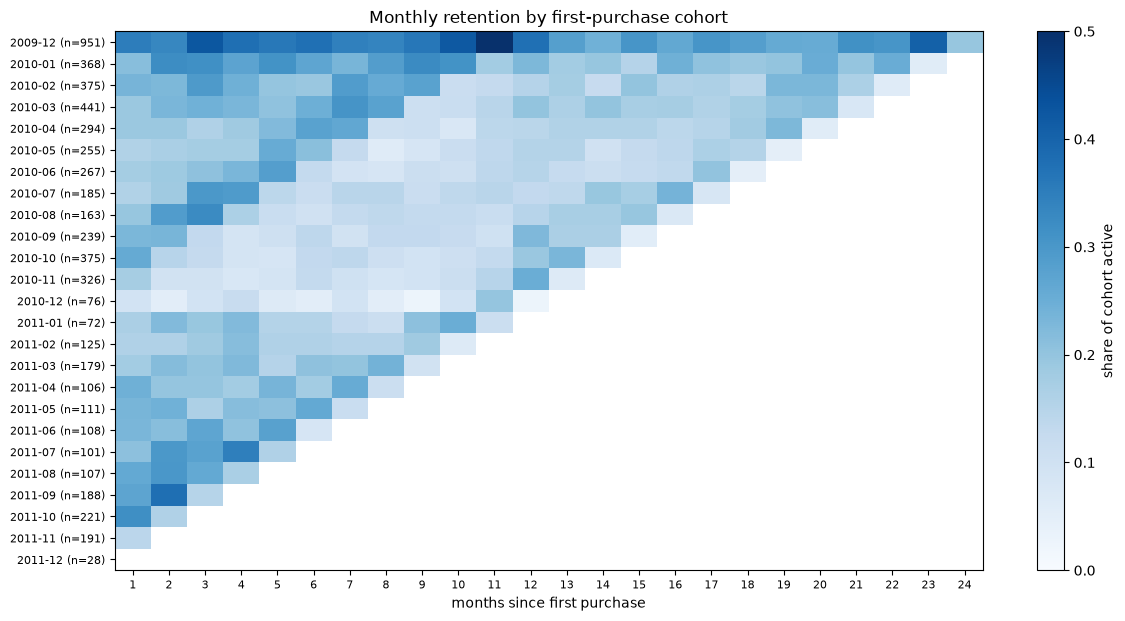

months_since_first,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort,,,,,,,,,,,,,
2009-12,1.00,0.35,0.33,0.42,0.38,0.36,0.38,0.34,0.34,0.36,0.42,0.50,0.38
2010-01,1.00,0.21,0.32,0.32,0.27,0.31,0.27,0.23,0.29,0.33,0.31,0.18,0.23
2010-02,1.00,0.23,0.23,0.29,0.25,0.20,0.19,0.29,0.26,0.28,0.11,0.13,0.15
2010-03,1.00,0.19,0.23,0.24,0.23,0.20,0.25,0.31,0.28,0.11,0.12,0.15,0.20
2010-04,1.00,0.19,0.19,0.16,0.18,0.22,0.28,0.27,0.11,0.11,0.07,0.14,0.14
2010-05,1.00,0.16,0.17,0.18,0.18,0.25,0.21,0.13,0.06,0.08,0.11,0.13,0.15
2010-06,1.00,0.18,0.19,0.21,0.23,0.28,0.13,0.09,0.08,0.11,0.10,0.14,0.15
2010-07,1.00,0.16,0.18,0.30,0.29,0.14,0.11,0.15,0.15,0.11,0.14,0.15,0.13
2010-08,1.00,0.20,0.29,0.33,0.17,0.12,0.10,0.13,0.13,0.13,0.13,0.12,0.15


In [14]:
clean = pd.read_csv("clean_transactions.csv", parse_dates=["InvoiceDate"], usecols=["Invoice", "InvoiceDate", "CustomerID", "is_return"])
active = clean[~clean["is_return"]].assign(month=lambda d: d["InvoiceDate"].dt.to_period("M"))[["CustomerID", "month"]].drop_duplicates()
active["cohort"] = active.groupby("CustomerID")["month"].transform("min")
active["months_since_first"] = (active["month"] - active["cohort"]).apply(lambda p: p.n)

counts = active.pivot_table(index="cohort", columns="months_since_first", values="CustomerID", aggfunc="nunique")
retention = counts.div(counts[0], axis=0)

fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(retention.iloc[:, 1:].values, aspect="auto", cmap="Blues", vmin=0, vmax=.5)
ax.set_yticks(range(len(retention))); ax.set_yticklabels([f"{c} (n={int(n):,})" for c, n in counts[0].items()], fontsize=8)
ax.set_xticks(range(retention.shape[1] - 1)); ax.set_xticklabels(retention.columns[1:], fontsize=8)
ax.set_xlabel("months since first purchase"); ax.set_title("Monthly retention by first-purchase cohort")
fig.colorbar(im, ax=ax, label="share of cohort active"); plt.show()
retention.iloc[:, :13]

In [15]:
# Average retention curve, weighting each cohort by size; excluding the left-censored 2009-12 cohort
c = counts[counts.index > pd.Period("2009-12", "M")]
observed_size = c.notna().mul(c[0], axis=0).sum()          # only cohorts old enough to reach month k
avg_curve = c.sum() / observed_size
avg_curve.iloc[:13].rename("weighted retention, cohorts from 2010-01").to_frame().T

months_since_first,0,1,2,3,4,5,6,7,8,9,10,11,12
"weighted retention, cohorts from 2010-01",1.00,0.21,0.21,0.21,0.19,0.19,0.18,0.18,0.16,0.15,0.13,0.14,0.18


### 8.7 Lưu kết quả

* `customer_rfm_train.csv`, `customer_rfm_test.csv`: một dòng mỗi khách trong population, gồm các đặc trưng RFM và nhóm. Đây cũng là đầu vào đặc trưng cho bước mô hình, nối theo `CustomerID` với `modeling_base_*.csv`.
* `segment_profile.csv`: hồ sơ nhóm của cả hai snapshot.

In [16]:
for name in SNAPSHOTS:
    out = rfm[name].copy()
    out.insert(0, "split", name)
    out.to_csv(f"customer_rfm_{name}.csv", index=False)
pd.concat(profile, names=["split"]).to_csv("segment_profile.csv")
print("Saved customer_rfm_train.csv, customer_rfm_test.csv, segment_profile.csv")

Saved customer_rfm_train.csv, customer_rfm_test.csv, segment_profile.csv


### 8.8 Key findings

| # | Phát hiện | Bằng chứng | Ý nghĩa |
|---|-----------|------------|---------|
| 1 | Doanh thu tập trung rất mạnh | Top 10% khách chiếm 59% doanh thu cửa sổ quan sát train, top 1% chiếm 28% | Nhận diện đúng nhóm giá trị cao quan trọng hơn mọi nhóm khác |
| 2 | Mỗi trục R, F, M một mình đã tách được tương lai | Train: tỷ lệ mua lại 56% / 33% / 23% theo R (≤90 / 91-180 / >180 ngày); 22% / 42% / 75% theo F (1 / 2-3 / 4+); 28% / 60% / 88% theo M | Các ngưỡng đọc từ EDA có cơ sở, không chọn tuỳ ý |
| 3 | Bảy nhóm tách rõ hành vi 6 tháng sau cutoff | Train: tỷ lệ mua lại từ 23% (Lapsed) đến 91% (Champions); chi tiêu tương lai bình quân của Champions gấp 6.5 lần mức chung | Nhóm có giá trị dự báo thật, không chỉ mô tả quá khứ |
| 4 | Champions giữ phần lớn giá trị tương lai | 9% khách, 60% doanh thu tương lai ở train (59% ở test) | Mất một khách Champions thiệt hại hơn mất hàng chục khách nhóm khác |
| 5 | Thứ hạng các nhóm ổn định khi áp ngưỡng train lên test | Tương quan hạng Spearman giữa train và test: 0.96 (tỷ lệ mua lại), 1.00 (lift chi tiêu) | Luật dùng được cho kỳ sau mà không cần tính lại ngưỡng |
| 6 | Mức tuyệt đối thay đổi theo mùa | Mọi nhóm có tỷ lệ mua lại ở test cao hơn train (mùa cao điểm Q4); tỷ trọng Lapsed tăng từ 17% lên 39% vì cửa sổ quan sát test chứa nhiều khách mua một lần trong Q4-2010 | Dùng nhóm để xếp thứ tự ưu tiên, không dùng tỷ lệ của một kỳ làm dự báo tuyệt đối cho kỳ khác |
| 7 | Khách mới mua một lần và khách Developing rất dễ rơi rụng | Trong số khách có mặt ở cả hai snapshot: 75% One-time recent và 55% Developing ở train chuyển sang Lapsed ở test | Đây là điểm cần can thiệp sớm để khách hình thành thói quen mua |
| 8 | VIP at risk nhỏ nhưng còn cứu được | 35 khách ở train; 46% mua lại, chi tiêu tương lai gấp 1.6 lần mức chung; 32% trở lại Champions ở test | Nhóm đáng đầu tư win-back cá nhân hoá, chi phí giới hạn vì nhóm nhỏ |
| 9 | Giữ chân theo cohort thấp và phẳng | Cohort từ 2010-01: khoảng 21% khách quay lại ở tháng 1, giảm dần còn khoảng 13-18% sau 10-12 tháng | Phần lớn khách mới không quay lại, nên giữ được khách đã mua lại có giá trị cao |

### 8.9 Quy tắc ứng xử theo nhóm (định hướng)

Tỷ lệ mua lại trong bảng hồ sơ là **mức cơ sở**: hành vi khi cửa hàng không có can thiệp đặc biệt nào được ghi nhận. Nhóm đã có mức cơ sở cao thì giảm giá chủ yếu là "tặng tiền" cho giao dịch vốn sẽ xảy ra. Đây là nguồn chính của giảm giá quá mức.

| Nhóm | Mục tiêu | Ứng xử | Mức giảm giá |
|---|---|---|---|
| Champions | Giữ chân, không làm mòn biên | Chăm sóc riêng, ưu tiên hàng mới, ưu đãi phi giá (giao hàng, hạn mức) | **Không** giảm giá đại trà |
| VIP at risk | Kéo về trước khi mất hẳn | Liên hệ cá nhân, tìm nguyên nhân, ưu đãi win-back | Cao nhất trong các nhóm, nhưng có giới hạn vì nhóm nhỏ |
| Loyal | Tăng giá trị đơn | Gợi ý combo, ngưỡng miễn phí vận chuyển | Thấp, chỉ khi có điều kiện tăng giá trị đơn |
| Developing | Biến mua lại thành thói quen | Ưu đãi có thời hạn cho lần mua tiếp theo | Vừa phải, có điều kiện |
| One-time recent | Kích hoạt lần mua thứ hai | Chuỗi email chào mừng, gợi ý sản phẩm | Nhỏ, một lần |
| Cooling | Nhắc nhở trước khi rời đi | Nhắc nhở tự động, ưu đãi ngắn hạn | Nhỏ |
| Lapsed | Tái kích hoạt với chi phí thấp nhất | Chiến dịch tự động hàng loạt | Rất thấp hoặc không |

**Giới hạn:** dữ liệu không có chi phí, chiết khấu hay lịch sử chiến dịch, nên bảng trên chỉ là định hướng. Mức ưu đãi cụ thể và biên lợi nhuận kỳ vọng sẽ được mô phỏng ở bước luật nhắm khuyến mãi, với giả định tỷ lệ phản hồi và mức giảm giá rõ ràng.